# Análise exploratória

In [ ]:
# Bibliotecas
import os
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.parse
from sqlalchemy import create_engine

# Configurações globais de layout
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [ ]:
# Sobe dois níveis para encontrar o .env na raiz (notebooks/ -> raiz/)
caminho_env = Path.cwd().parent / ".env" if (Path.cwd().parent / ".env").exists() else Path(".env")
load_dotenv(dotenv_path=caminho_env, override=True)

USUARIO = os.getenv("MYSQL_USER", "root")
SENHA = urllib.parse.quote_plus(os.getenv("MYSQL_PASSWORD", ""))
HOST = os.getenv("MYSQL_HOST", "localhost")
PORTA = os.getenv("MYSQL_PORT", "3306")
BANCO = os.getenv("MYSQL_DATABASE", "crm_propensity_banking")

# Criar a engine de conexão
conexao_str = f"mysql+pymysql://{USUARIO}:{SENHA}@{HOST}:{PORTA}/{BANCO}"
engine = create_engine(conexao_str)


In [3]:
# Consulta SQL direta para carregar toda a tabela
query = "SELECT * FROM stg_bank_marketing;"

# Carregar diretamente para o DataFrame do pandas
df = pd.read_sql(query, con=engine)

# Exibir as primeiras 5 linhas e a dimensão dos dados
print(f"Dimensões do DataFrame: {df.shape}")
df.head()

Dimensões do DataFrame: (45211, 17)


,age,job,marital,education,default_credit,balance,housing,loan,contact,day,month,campaign,pdays_since_contact,previous_contact,previous,poutcome,target
0,58,management,married,tertiary,default,2143,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
1,44,technician,single,secondary,default,29,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
2,33,entrepreneur,married,secondary,default,2,yes,yes,unknown,5,may,1,NaN,0,0,unknown,0
3,47,blue-collar,married,unknown,default,1506,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
4,33,unknown,single,unknown,default,1,no,no,unknown,5,may,1,NaN,0,0,unknown,0


1. Dimensão e tipos dos dados.

In [4]:
print("Dimensão:", df.shape)

Dimensão: (45211, 17)


In [5]:
print(df.dtypes)

age                      int64
job                        str
marital                    str
education                  str
default_credit             str
balance                  int64
housing                    str
loan                       str
contact                    str
day                      int64
month                      str
campaign                 int64
pdays_since_contact    float64
previous_contact         int64
previous                 int64
poutcome                   str
target                   int64
dtype: object


2. Valores ausentes e categorias unknown.

In [6]:
print(df.isna().sum().sort_values(ascending=False).head(10))

pdays_since_contact    36954
age                        0
job                        0
education                  0
marital                    0
balance                    0
housing                    0
loan                       0
default_credit             0
contact                    0
dtype: int64


3. Distribuição de target e taxa geral de conversão.

In [7]:
print("\nDistribuição do target:")
print(df["target"].value_counts(normalize=True).round(3))


Distribuição do target:
target
0    0.883
1    0.117
Name: proportion, dtype: float64


4. Taxa de conversão por ocupação, escolaridade, empréstimo habitacional e resultado de campanha anterior.

               count      mean
job                           
student          938  0.286780
retired         2264  0.227915
unemployed      1303  0.155027
management      9458  0.137556
admin.          5171  0.122027
self-employed   1579  0.118429
unknown          288  0.118056
technician      7597  0.110570
services        4154  0.088830
housemaid       1240  0.087903
entrepreneur    1487  0.082717
blue-collar     9732  0.072750


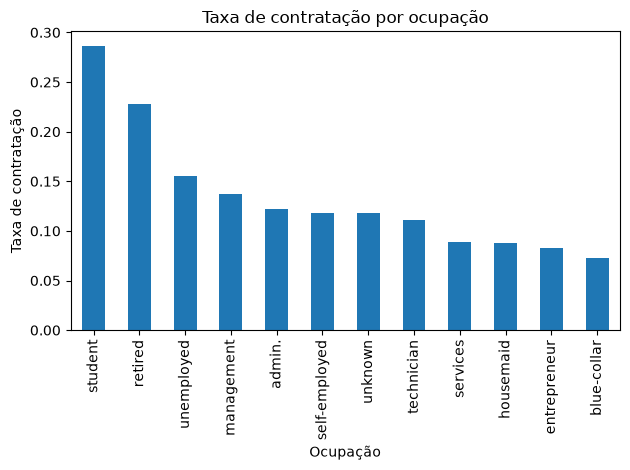

In [8]:
conversion_by_job = (
    df.groupby("job", dropna=False)["target"]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)

print(conversion_by_job)

conversion_by_job["mean"].plot(kind="bar")
plt.title("Taxa de contratação por ocupação")
plt.ylabel("Taxa de contratação")
plt.xlabel("Ocupação")
plt.tight_layout()
plt.show()

5. Distribuição de idade e saldo.

C:\Users\yumi_\AppData\Local\Temp\ipykernel_16080\2950271601.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='balance', ax=axes[1], palette='Set2')


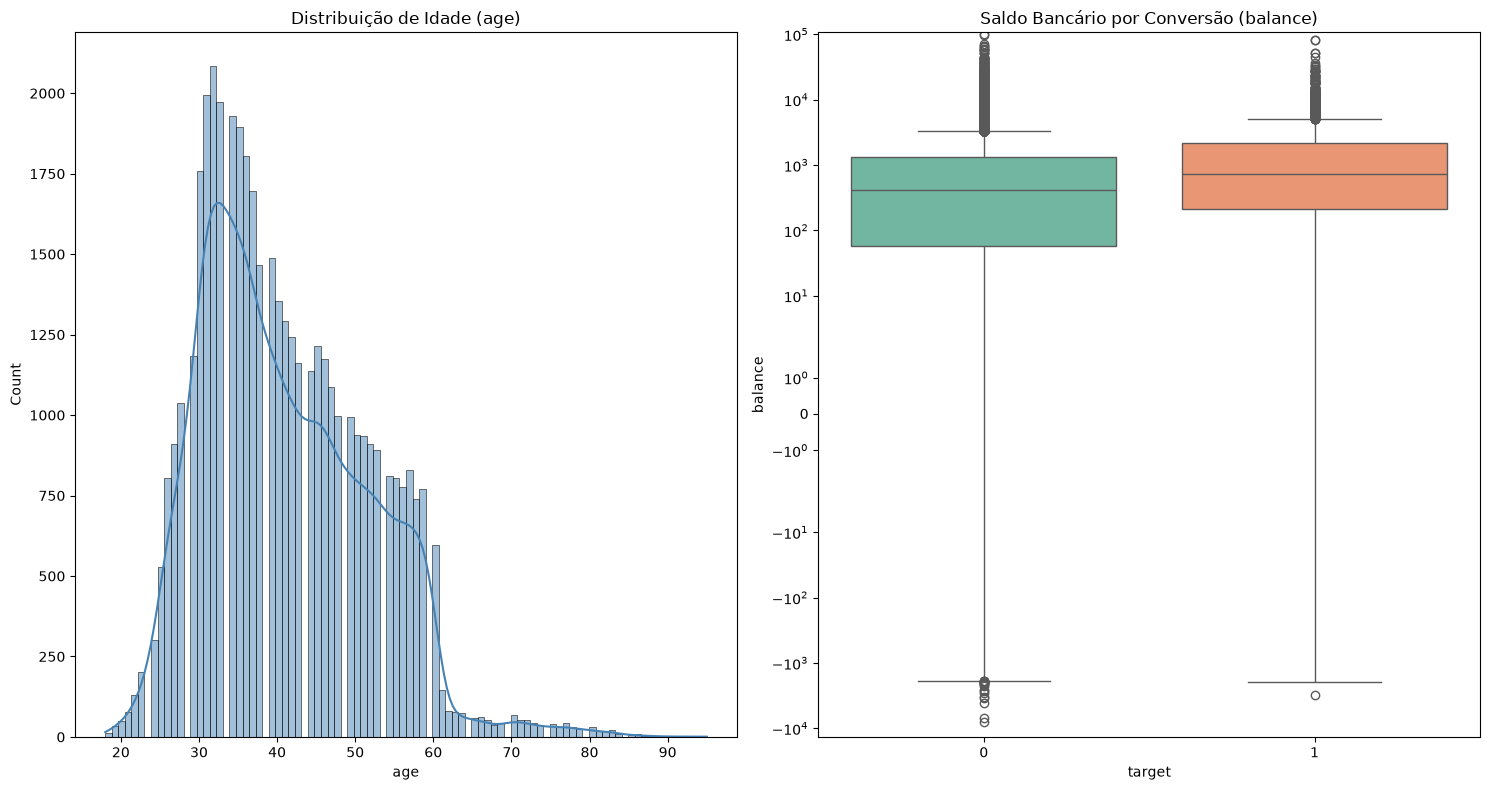

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Idade
sns.histplot(data=df, x='age', kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Distribuição de Idade (age)")

# Saldo bancário (usando escala logarítmica ou limite para lidar com outliers)
sns.boxplot(data=df, x='target', y='balance', ax=axes[1], palette='Set2')
axes[1].set_title("Saldo Bancário por Conversão (balance)")
axes[1].set_yscale('symlog')  # Escala simétrica para aceitar saldos negativos

plt.tight_layout()
plt.show()

6. Discussão sobre desbalanceamento e limitações do conjunto de dados.

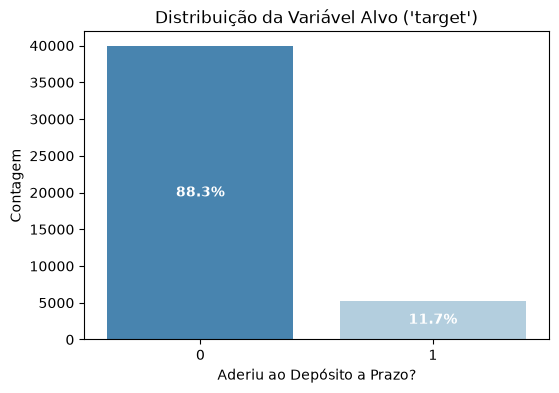

In [15]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='target', hue='target', palette='Blues_r', legend=False)

# Adiciona a porcentagem no topo de cada barra
total = len(df)
for p in ax.patches:
    pct = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(pct, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.title("Distribuição da Variável Alvo ('target')")
plt.xlabel("Aderiu ao Depósito a Prazo?")
plt.ylabel("Contagem")
plt.show()

7. Matriz de Correlação

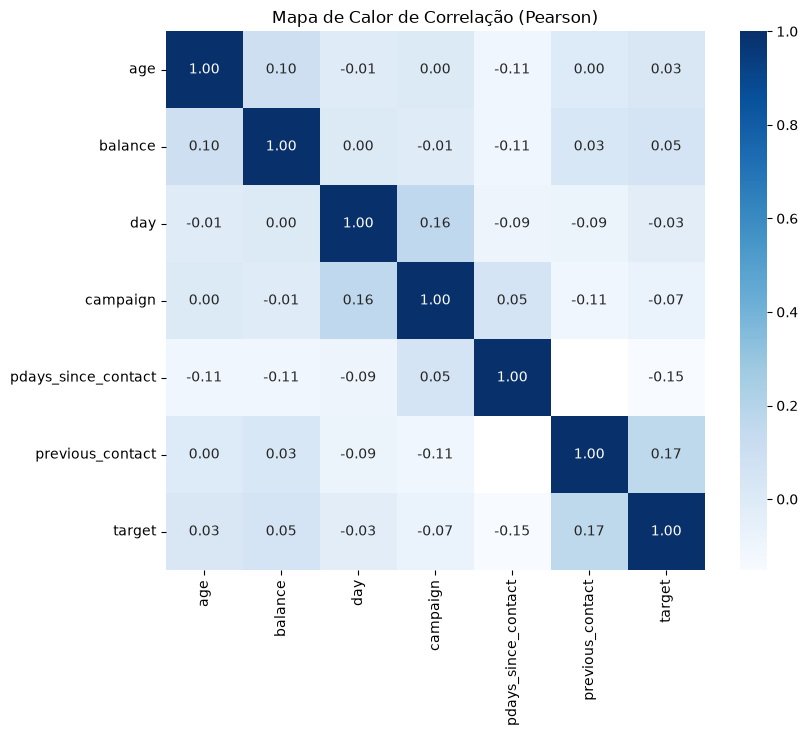

In [14]:
colunas_num = ['age', 'balance', 'day', 'campaign', 'pdays_since_contact', 'previous_contact', 'target']
colunas_cat = ['poutcome', 'target']

# Mapa de calor de correlação
df[colunas_num].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(df[colunas_num].corr(), annot=True, fmt=".2f", cmap='Blues', cbar=True, square=True)
plt.title("Mapa de Calor de Correlação (Pearson)")
plt.show()